In [1]:
from pysammos.utils.config_loader import load_config
from pysammos.coarse_graining import CoarseGraining

Hello from pysammos
Loading macroscopic_fields package...
Loading data_read package...
Loading particle_phase package...
Loading spatial_weights package...
Loading neighbour_search package...
Loading grid_generation package...
Loading data_handle package...
Loading data_write package...


In [46]:
import numpy as np
import matplotlib.pyplot as plt
from pysammos.data_write.h5.writer import H5XarrayManager
from pysammos.post_averaging.profiles import VerticalIntegrator
import pyvista as pv

## Run the coarse graining

In [21]:
# Load the configuration from the ini file
cfg = load_config("./config.ini")  
print("-------------------- config.ini file read --------------------")
# Initialize the CoarseGraining class with the loaded configuration
CG = CoarseGraining(
    particle_path=cfg["particles_path"],
    contacts_path=cfg["contacts_path"],
    output_path=cfg["output_path"],
    start_timestep=cfg["t0"],
    end_timestep=cfg["tf"],
    dt_time_step=cfg["dt"],
    t_pad=cfg["t_pad"],
    DEM_keymap=cfg["key_mapping"],
    DEM_software=cfg["DEM_software"],
    grid_info=cfg["grid_info"],
    weight_function=cfg["smoothing_function"],
    fields_to_export=cfg["fields_to_export"],
    time_average=cfg["time_average"],
    ignore_phases=cfg["partialignore"],
    h5_output=cfg["h5_output"],
    vkthdf_output=cfg["vkthdf_output"],
                    ) 
print("  ") ; print("-------------------- CoarseGraining class initialised --------------------")

-------------------- config.ini file read --------------------
Output path created: ./PysammosCG/
  
-------------------- CoarseGraining class initialised --------------------


In [22]:
# 1. Load the size-relevant particle data for the first time step
Bounds_t0, Diameter_t0, Density_t0, Mass_t0, GlobalID_t0 = CG.data_sampling()

Sampling data for the first time step to obtain particle properties and bounds ... 
XML-based PolyData detected.


In [23]:
# 2. Calculate the particle size range
CG.get_particle_size_statistics(Diameter_t0, Mass_t0)
print(">> Particle size statistics: ") 
print("       d43: ", CG.d43)
print("       dmax: ", CG.dmax)
print("       d50: ", CG.d50)
print("       d32: ", CG.d32)
print("       drms: ", CG.drms)

>> Particle size statistics: 
       d43:  0.01651367411185649
       dmax:  0.019993
       d50:  0.016306963
       d32:  0.016109877148148044
       drms:  0.015422490500786803


In [24]:
# 3. Get the phases
CG.get_particle_phases(Diameter_t0, Density_t0, GlobalID_t0, 8)
print(">> Phases: ")
print("       Diameters: ", CG.phases[:,0])
print("       Densities: ", CG.phases[:,1])

Ignoring phases. Using mean density and d50 as phase.
>> Phases: 
       Diameters:  [0.01610988]
       Densities:  [2700.]


In [25]:
# 4. Calculate the CG grid spacing
CG.set_resolution(CG.d43) # here you can input different number, to make w and c bigger or smaller 
print(">> Coarse Graining resolution: ")
print("       c:", CG.c)
print("       w:", CG.w)

>> Coarse Graining resolution: 
       c: 0.024770511167784733
       w: 0.012385255583892366


In [26]:
# 5. Generate the CG grid
CG.generate_grid()
print(">> Grid: ")
print("       Grid Points: ", CG.GridPoints.shape, "First Point: ", CG.GridPoints[0])
print("       Nodes: ", CG.Nodes)
print("       Spacing: ", CG.Spacing)

Generating Grid with Customised Grid Ranges
Customised grid bounds: x = [0.00105, 0.5], y = [0.001, 0.24], z = [None, None], x_transect = None, y_transect = None, z_transect = 0.0
>> Grid: 
       Grid Points:  (882, 3) First Point:  [0.00105 0.001   0.     ]
       Nodes:  [42 21  1]
       Spacing:  [0.01216951 0.01195   ]


In [27]:
# 6. Calculate the CG fields
CG.fields_in_time()

 
-------------------- Calculating Coarse Grained Fields --------------------
 
---> Time step 0: time 0150 ................................................
Loading data ... 
  Particle data loaded
  Repeated pairs in contact data:  1142
  Contact data loaded and mapped
  Coordination number not required. Skipping its calculation.
... data loaded
Matching particles to grid points ...
... particles assigned to grid nodes
Computing weights ...
  Using Lucy kernel with cutoff 0.024770511167784733 and search sampling factor 1000
... weights computed
Computing Coarse Graining fields...
  volume fraction done
  mixture density done
  momentum density done
  velocity done
  velocity gradient done
  kinetic tensor done
  contact tensor done
  d43 done
  d32 done
  frabric tensor done
  particle density done
  total stress done
  pressure done
  granular temp done
  shear rate done
  inertial number done
  mu done
... fields computed
Writing results for timestep 150...
  File successfully updat

## Time average results

In [44]:
# open 
from pysammos.data_write.h5.writer import H5XarrayManager 
manager = H5XarrayManager("/exports/csce/datastore/geos/users/s1857688/Coarse_Graining/pysammos/examples/bedload_transport/PysammosCG/CG_GranularTemperature_slices_time_averaged.h5")
slices_gt_tav = manager.h5_to_xarray()

Processing key: granular_temperature_Kamrin
Processing key: granular_temperature_LAMMPS
Processing key: positions
Processing key: time


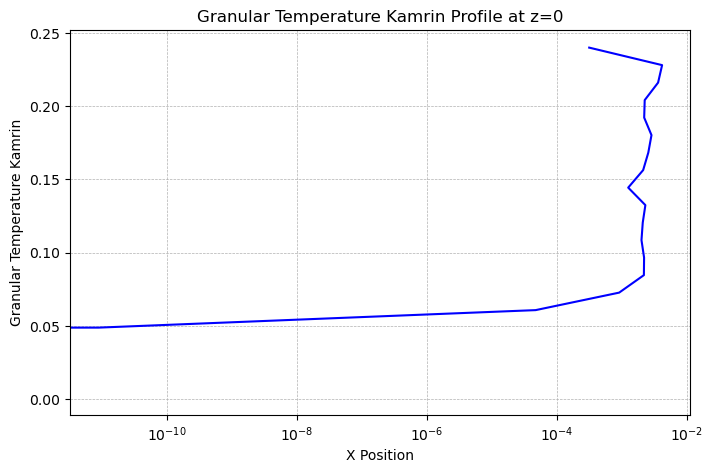

In [54]:
fig, ax = plt.subplots(figsize=(8,5))
ax.plot(slices_gt_tav.granular_temperature_Kamrin[0,:,0], slices_gt_tav.positions[:, 1], color="blue")
ax.set_xlabel('X Position')
ax.set_ylabel('Granular Temperature Kamrin')
ax.set_title('Granular Temperature Kamrin Profile at z=0')
ax.grid(visible=True, which='both', linestyle='--', linewidth=0.5)
ax.set_xscale('log')
plt.show()

## compare to old results (single time)

#### a) slice averages

In [28]:
# Load data
manager = H5XarrayManager("./PysammosCG/CG_Lucy_Monodisperse.h5")
bedload_CG = manager.h5_to_xarray()

Processing key: density_mixture
Processing key: fabric_tensor
Processing key: frictional_coefficient_01_Pxy
Processing key: frictional_coefficient_01_Pxyz
Processing key: frictional_coefficient_01_Py
Processing key: frictional_coefficient_Dxy_Pxy
Processing key: frictional_coefficient_Dxy_Pxyz
Processing key: frictional_coefficient_Dxy_Py
Processing key: frictional_coefficient_Dxyz_Pxy
Processing key: frictional_coefficient_Dxyz_Pxyz
Processing key: frictional_coefficient_Dxyz_Py
Processing key: granular_temperature_x
Processing key: granular_temperature_xyz
Processing key: granular_temperature_y
Processing key: granular_temperature_z
Processing key: inertial_number_Sxy_Pxy_d32
Processing key: inertial_number_Sxy_Pxy_d43
Processing key: inertial_number_Sxy_Pxyz_d32
Processing key: inertial_number_Sxy_Pxyz_d43
Processing key: inertial_number_Sxy_Py_d32
Processing key: inertial_number_Sxy_Py_d43
Processing key: positions
Processing key: pressure_x
Processing key: pressure_xy
Processing k

In [29]:
# Perform vertical integration
VI = VerticalIntegrator(bedload_CG, 'y')
vertical_ds_general = VI.integration()

Starting integration along profile dimension: y
Completed integration along profile dimension: y


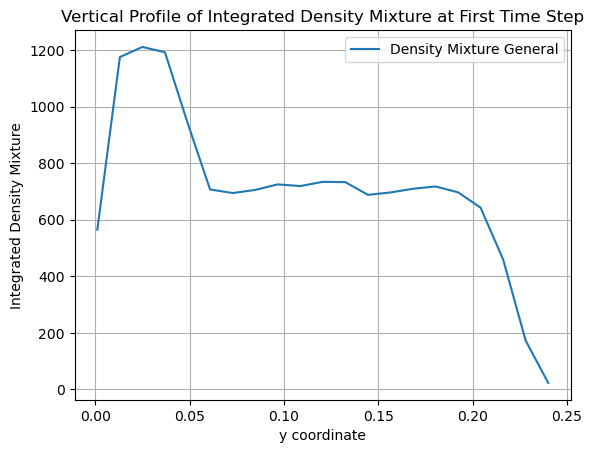

In [30]:
# plot the profile of density_mixture of the first time step
vertical_ds_general['density_mixture'].isel(time=0).plot.line(x='y', label='Density Mixture General')
plt.xlabel('y coordinate')
plt.ylabel('Integrated Density Mixture')
plt.title('Vertical Profile of Integrated Density Mixture at First Time Step')
plt.legend()
plt.grid()
plt.show()

#### b) other

In [31]:
manager = H5XarrayManager("./PysammosCG/CG_Lucy_Monodisperse.h5")
bedload_CG = manager.h5_to_xarray()

Processing key: density_mixture
Processing key: fabric_tensor
Processing key: frictional_coefficient_01_Pxy
Processing key: frictional_coefficient_01_Pxyz
Processing key: frictional_coefficient_01_Py
Processing key: frictional_coefficient_Dxy_Pxy
Processing key: frictional_coefficient_Dxy_Pxyz
Processing key: frictional_coefficient_Dxy_Py
Processing key: frictional_coefficient_Dxyz_Pxy
Processing key: frictional_coefficient_Dxyz_Pxyz
Processing key: frictional_coefficient_Dxyz_Py
Processing key: granular_temperature_x
Processing key: granular_temperature_xyz
Processing key: granular_temperature_y
Processing key: granular_temperature_z
Processing key: inertial_number_Sxy_Pxy_d32
Processing key: inertial_number_Sxy_Pxy_d43
Processing key: inertial_number_Sxy_Pxyz_d32
Processing key: inertial_number_Sxy_Pxyz_d43
Processing key: inertial_number_Sxy_Py_d32
Processing key: inertial_number_Sxy_Py_d43
Processing key: positions
Processing key: pressure_x
Processing key: pressure_xy
Processing k

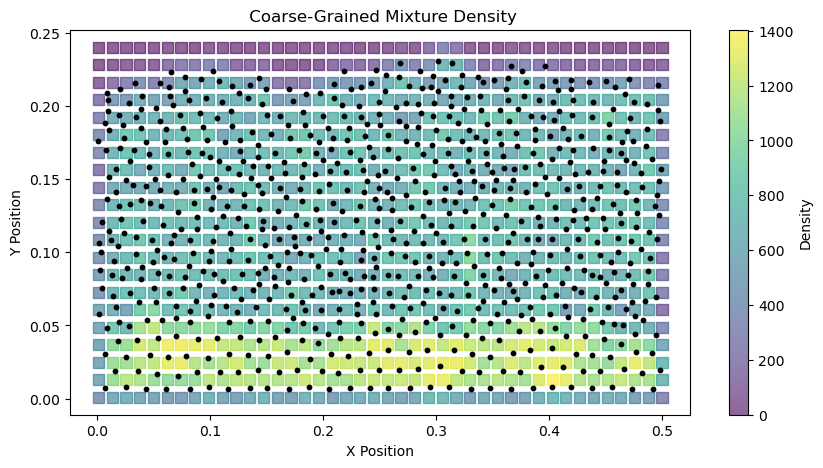

In [34]:
# Create figure and axis
fig = plt.figure(figsize=(10,5))
ax = fig.add_subplot(111)

# Plot DEM particle positions 
bedload_DEM = pv.read('../data_examples/bedload_transport/DEM_data/DES_FB1_0150.vtp')
bedload_particles = bedload_DEM.points
x_particle = bedload_particles[:, 0]; y_particle = bedload_particles[:, 1]
ax.scatter(x_particle, y_particle, s=10, c='k', alpha=1, label='Particle Positions', zorder=3)

# Plot the CG data
x = np.asarray(bedload_CG.positions[:, 0]) 
y = np.asarray(bedload_CG.positions[:, 1])
z = np.asarray(bedload_CG.positions[:, 2])
var = np.asarray(bedload_CG.density_mixture.values[0, :])
sc = ax.scatter(x, y, s=65, c=var, 
                cmap='viridis', alpha=0.6, label='CG Density', 
                zorder=1, marker='s')

# Add colorbar and labels
plt.colorbar(sc, ax=ax, label='Density')
ax.set_xlabel('X Position')
ax.set_ylabel('Y Position')
ax.set_title(' Coarse-Grained Mixture Density')
plt.show()

In [35]:
# initialise data reader manager
manager_gt = H5XarrayManager("./PysammosCG/CG_GranularTemperature_slices.h5")
slices_gt = manager_gt.h5_to_xarray()

Processing key: granular_temperature_Kamrin
Processing key: granular_temperature_LAMMPS
Processing key: positions
Processing key: time


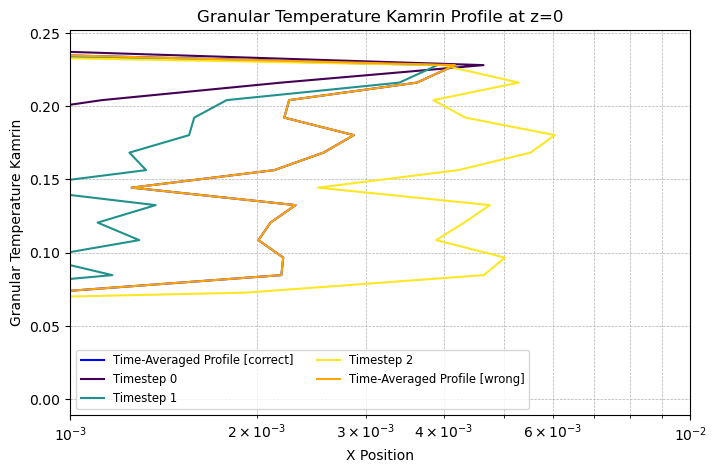

In [58]:
fig, ax = plt.subplots(figsize=(8,5))
num_timesteps = slices_gt.granular_temperature_Kamrin.shape[0]
colors = plt.cm.viridis(np.linspace(0, 1, num_timesteps))

ax.plot(slices_gt_tav.granular_temperature_Kamrin[0,:,0], slices_gt_tav.positions[:, 1], color="blue", label='Time-Averaged Profile [correct]')

for i in range(num_timesteps):
    ax.plot(slices_gt.granular_temperature_Kamrin[i,:,0], slices_gt.positions[:, 1], color=colors[i], label=f'Timestep {i}')
ax.plot(slices_gt.granular_temperature_Kamrin[:,:,0].mean(axis=0), slices_gt.positions[:, 1], color="orange", label='Time-Averaged Profile [wrong]')

ax.set_xlabel('X Position')
ax.set_ylabel('Granular Temperature Kamrin')
ax.set_title('Granular Temperature Kamrin Profile at z=0')
ax.legend(loc='best', fontsize='small', ncol=2)
#gridlines
ax.grid(visible=True, which='both', linestyle='--', linewidth=0.5)
# log scale x axis
ax.set_xscale('log')
ax.set_xlim([1e-3, 1e-2])  # Set x-axis limits
plt.show()

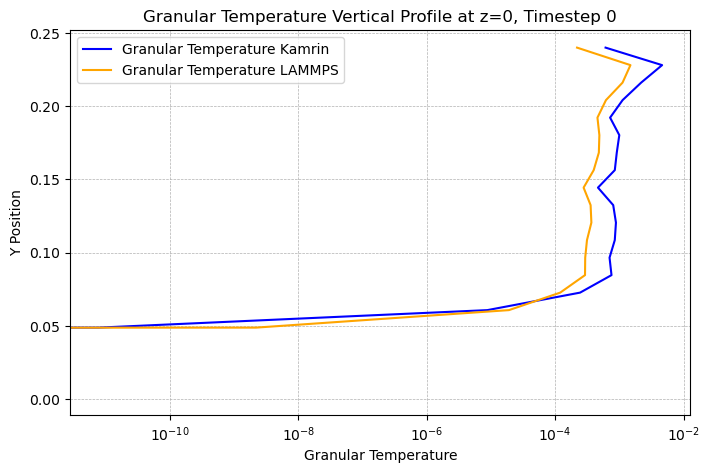

In [37]:
# plot first time step vertical profile comparing Kamrin and LAMMPS
fig, ax = plt.subplots(figsize=(8,5))
ax.plot(slices_gt.granular_temperature_Kamrin[0,:,0], slices_gt.positions[:, 1], label='Granular Temperature Kamrin', color='blue')
ax.plot(slices_gt.granular_temperature_LAMMPS[0,:,0], slices_gt.positions[:, 1], label='Granular Temperature LAMMPS', color='orange')
ax.set_xlabel('Granular Temperature')
ax.set_ylabel('Y Position')
ax.set_title('Granular Temperature Vertical Profile at z=0, Timestep 0')
#gridlines
ax.grid(visible=True, which='both', linestyle='--', linewidth=0.5)
# log scale x axis
ax.set_xscale('log')
ax.legend()
plt.show()  

## Plot difference of time averages for non-linear fields

In [59]:
manager_ts = H5XarrayManager("./PysammosCG/CG_Lucy_Monodisperse.h5"); ts = manager_ts.h5_to_xarray()
manager_tav = H5XarrayManager("./PysammosCG/CG_Lucy_Monodisperse_time_averaged.h5"); tav = manager_tav.h5_to_xarray()

Processing key: density_mixture
Processing key: fabric_tensor
Processing key: frictional_coefficient_01_Pxy
Processing key: frictional_coefficient_01_Pxyz
Processing key: frictional_coefficient_01_Py
Processing key: frictional_coefficient_Dxy_Pxy
Processing key: frictional_coefficient_Dxy_Pxyz
Processing key: frictional_coefficient_Dxy_Py
Processing key: frictional_coefficient_Dxyz_Pxy
Processing key: frictional_coefficient_Dxyz_Pxyz
Processing key: frictional_coefficient_Dxyz_Py
Processing key: granular_temperature_x
Processing key: granular_temperature_xyz
Processing key: granular_temperature_y
Processing key: granular_temperature_z
Processing key: inertial_number_Sxy_Pxy_d32
Processing key: inertial_number_Sxy_Pxy_d43
Processing key: inertial_number_Sxy_Pxyz_d32
Processing key: inertial_number_Sxy_Pxyz_d43
Processing key: inertial_number_Sxy_Py_d32
Processing key: inertial_number_Sxy_Py_d43
Processing key: positions
Processing key: pressure_x
Processing key: pressure_xy
Processing k

In [62]:
I_tav = tav.inertial_number_Sxy_Pxy_d32[0,:]
I_ts_averaged = ts.inertial_number_Sxy_Pxy_d32.mean(dim='time')

In [63]:
# print shapes 
print("Shape of time-averaged inertial number (I_tav):", I_tav.shape)
print("Shape of time-averaged inertial number from time series (I_ts_averaged):", I_ts_averaged.shape)

Shape of time-averaged inertial number (I_tav): (882,)
Shape of time-averaged inertial number from time series (I_ts_averaged): (882,)


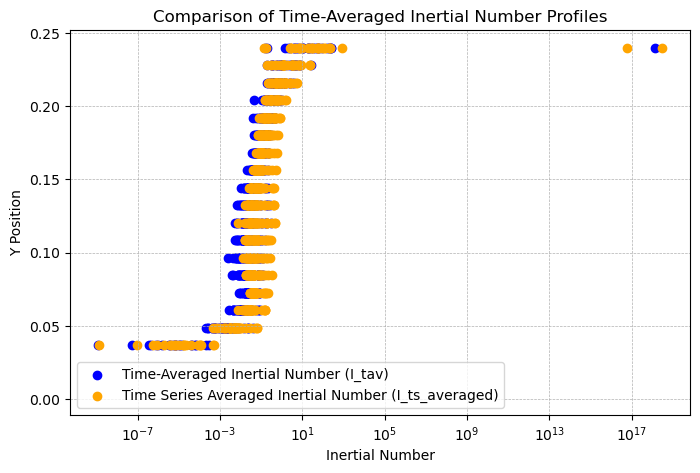

In [67]:
# plot difference between time-averaged inertial number and time series averaged inertial number
fig, ax = plt.subplots(figsize=(8,5))
ax.scatter(I_tav, tav.positions[:, 1], label='Time-Averaged Inertial Number (I_tav)', color='blue')
ax.scatter(I_ts_averaged,  ts.positions[:, 1], label='Time Series Averaged Inertial Number (I_ts_averaged)', color='orange')
ax.set_xlabel('Inertial Number')
ax.set_ylabel('Y Position')
ax.set_title('Comparison of Time-Averaged Inertial Number Profiles')
#gridlines
ax.grid(visible=True, which='both', linestyle='--', linewidth=0.5)
# log scale x axis
ax.set_xscale('log')
plt.legend()
plt.show()